# Does V-JEPA 2-AC obey the rules of motion? A consistency audit of the released world model

**Question.** A world model that plans by rolling out imagined actions should respect a few basic rules that hold for a robot arm moving in free space. This notebook tests four of them on Meta's released V-JEPA 2-AC checkpoint, with frozen weights and no training:

1. **Dose-response.** A bigger action should change the prediction more, and the predicted latent should be closest to the real next frame at the true action size.
2. **Step-splitting.** Moving by `a` in one step should land in the same latent as moving by `a/K` in `K` steps.
3. **Path independence.** Three two-step paths with the same end pose, `(a/2, a/2)`, `(a, 0)` and `(0, a)`, should give the same latent. So should `(x, z)` versus `(z, x)`.
4. **Reversal.** Doing `a` then `-a` should give the same latent as doing nothing for two steps.

A fifth test checks whether the planner's energy points at the true action direction, and tries a training-free fix: weighting each image patch by how much the robot can affect it. Tests 6 and 7 follow up on an anomaly found in tests 3 and 4 by placing the same action at each position of a rollout.

**Why it matters.** The V-JEPA 2 paper names error accumulation in autoregressive rollouts as a limitation. The rules above measure that failure directly, and each gap is also a training signal that needs no labels.

**Data.** The only robot transition shipped in the repo (`notebooks/franka_example_traj.npz`): two frames and two end-effector poses. This is one scene, so the results are a pilot, not a benchmark.

**Distance.** Everything uses the planner's own energy: mean absolute difference between layer-normalised latents.

In [2]:
# --- Setup: clone the official repo and install the two missing packages ---
import os, subprocess, sys

if not os.path.isdir("src") or not os.path.isdir("notebooks"):
    if not os.path.isdir("vjepa2"):
        subprocess.run(["git", "clone", "--depth", "1", "https://github.com/facebookresearch/vjepa2"], check=True)
    os.chdir("vjepa2")
ROOT = os.getcwd()
for p in (ROOT, os.path.join(ROOT, "notebooks")):
    if p not in sys.path:
        sys.path.insert(0, p)

try:
    import timm, einops  # noqa: F401
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "timm", "einops"], check=True)
print("repo root:", ROOT)

repo root: /content/vjepa2


In [3]:
import json
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch.nn import functional as F

from app.vjepa_droid.transforms import make_transforms
from utils.mpc_utils import compute_new_pose, poses_to_diff
from src.models import ac_predictor as acp
from src.models import vision_transformer as vit

# SMOKE_TEST=True swaps in a tiny random model so you can check the plumbing in seconds.
# Numbers from a smoke test mean nothing. Keep it False for real results.
SMOKE_TEST = os.environ.get("AUDIT_SMOKE_TEST", "0") == "1"
device = "cuda" if torch.cuda.is_available() else "cpu"
OUT = os.path.join(ROOT, "audit_outputs")
os.makedirs(OUT, exist_ok=True)
print("device:", device, "| smoke test:", SMOKE_TEST)

device: cuda | smoke test: False


/usr/local/lib/python3.13/dist-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)


## Load the released model

Note: at the commit I used, `src/hub/backbones.py` sets `VJEPA_BASE_URL = "http://localhost:8300"` (a leftover test value), so `torch.hub.load(..., "vjepa2_ac_vit_giant")` cannot download weights. The cell below builds the same architecture with the repo's own code and loads the public checkpoint directly.

In [4]:
CKPT_URL = "https://dl.fbaipublicfiles.com/vjepa2/vjepa2-ac-vitg.pt"
CKPT_PATH = os.path.join(ROOT, "vjepa2-ac-vitg.pt")
crop_size = 256

if SMOKE_TEST:
    enc_kw = dict(patch_size=16, img_size=(crop_size, crop_size), num_frames=64, tubelet_size=2, use_sdpa=True,
                  use_SiLU=False, wide_SiLU=True, uniform_power=False, use_rope=True)
    encoder = vit.vit_tiny(**enc_kw)
    predictor = acp.vit_ac_predictor(img_size=(crop_size, crop_size), patch_size=16, num_frames=64, tubelet_size=2,
                                     embed_dim=encoder.embed_dim, predictor_embed_dim=96, depth=2, num_heads=4)
else:
    from src.hub.backbones import _clean_backbone_key, _make_vjepa2_ac_model

    encoder, predictor = _make_vjepa2_ac_model(pretrained=False)
    if not os.path.isfile(CKPT_PATH):
        torch.hub.download_url_to_file(CKPT_URL, CKPT_PATH)
    try:
        sd = torch.load(CKPT_PATH, map_location="cpu", mmap=True)
    except Exception:
        sd = torch.load(CKPT_PATH, map_location="cpu", weights_only=False)
    print("encoder  :", encoder.load_state_dict(_clean_backbone_key(sd["encoder"]), strict=False))
    print("predictor:", predictor.load_state_dict(_clean_backbone_key(sd["predictor"]), strict=True))
    del sd

encoder = encoder.to(device).eval()
predictor = predictor.to(device).eval()
tokens_per_frame = int((crop_size // encoder.patch_size) ** 2)
grid = crop_size // encoder.patch_size
print(f"encoder params: {sum(p.numel() for p in encoder.parameters())/1e6:.0f}M | "
      f"predictor params: {sum(p.numel() for p in predictor.parameters())/1e6:.0f}M")

100%|██████████| 11.0G/11.0G [03:26<00:00, 57.0MB/s]


encoder  : <All keys matched successfully>
predictor: <All keys matched successfully>
encoder params: 1012M | predictor params: 305M


true action (dx, dy, dz): [0.0924, 0.031, 0.0843] | size: 0.1288 m


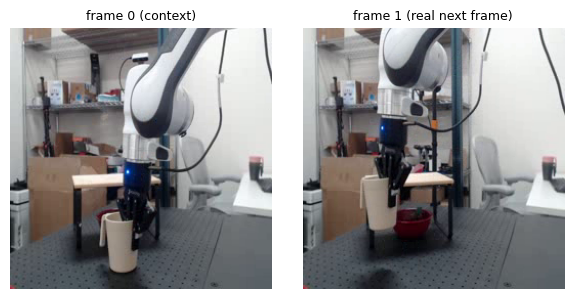

In [5]:
# --- Load the example Franka transition (same preprocessing as the official energy-landscape notebook) ---
transform = make_transforms(random_horizontal_flip=False, random_resize_aspect_ratio=(1.0, 1.0),
                            random_resize_scale=(1.0, 1.0), reprob=0.0, auto_augment=False,
                            motion_shift=False, crop_size=crop_size)

traj = np.load(os.path.join(ROOT, "notebooks", "franka_example_traj.npz"))
np_clips, np_states = traj["observations"], traj["states"]
clips = transform(np_clips[0]).unsqueeze(0).to(device)
states = torch.tensor(np_states, dtype=torch.float32, device=device)
a_gt = poses_to_diff(np_states[0, 0], np_states[0, 1]).float().to(device)  # true 7-D action

print("true action (dx, dy, dz):", [round(float(v), 4) for v in a_gt[:3]],
      "| size:", round(float(a_gt[:3].norm()), 4), "m")
fig, ax = plt.subplots(1, 2, figsize=(6, 3))
for i, t in enumerate(["frame 0 (context)", "frame 1 (real next frame)"]):
    ax[i].imshow(np_clips[0, i]); ax[i].set_title(t, fontsize=9); ax[i].axis("off")
plt.tight_layout(); plt.show()

## Core helpers

`rollout` is the same autoregressive loop the official planner uses: predict the next frame's latent, layer-normalise it, update the pose, append, repeat.

In [6]:
def dist(a, b):
    # Planner energy: mean |a - b| over tokens and channels. Returns one value per batch item.
    return (a - b).abs().mean(dim=(1, 2))


def token_map(a, b):
    # Same distance, kept per image patch: [B, grid, grid]
    return (a - b).abs().mean(dim=-1).view(-1, grid, grid)


@torch.no_grad()
def encode(c):
    B, C, T, H, W = c.size()
    c = c.permute(0, 2, 1, 3, 4).flatten(0, 1).unsqueeze(2).repeat(1, 1, 2, 1, 1)
    h = encoder(c)
    h = h.view(B, T, -1, h.size(-1)).flatten(1, 2)
    return F.layer_norm(h, (h.size(-1),))


@torch.no_grad()
def rollout(z0, s0, action_seq, chunk=8):
    # z0: [1, N, D], s0: [1, 1, 7], action_seq: [B, K, 7]. Returns the final latent of each sequence, [B, N, D].
    outs = []
    for i in range(0, action_seq.size(0), chunk):
        acts = action_seq[i:i + chunk].to(device=z0.device, dtype=z0.dtype)
        B, K, _ = acts.shape
        z = z0.repeat(B, 1, 1)
        s = s0.repeat(B, 1, 1)
        for k in range(K):
            a = acts[:, :k + 1]
            z_next = predictor(z, a, s)[:, -tokens_per_frame:]
            z_next = F.layer_norm(z_next, (z_next.size(-1),))
            s_next = compute_new_pose(s[:, -1:], a[:, -1:])
            z = torch.cat([z, z_next], dim=1)
            s = torch.cat([s, s_next], dim=1)
        outs.append(z[:, -tokens_per_frame:])
    return torch.cat(outs, dim=0)


def act(xyz):
    # Translation-only action: [dx, dy, dz, 0, 0, 0, 0], same form the planner samples.
    a = torch.zeros(7)
    a[:3] = torch.as_tensor(xyz, dtype=torch.float32)
    return a


def seq(*steps):
    # Stack per-step actions into one sequence [K, 7]
    return torch.stack([s.cpu() for s in steps], dim=0)


h = encode(clips)
z0, h1 = h[:, :tokens_per_frame], h[:, -tokens_per_frame:]
s0 = states[:, :1]
ZERO = act([0, 0, 0])
a_gt_t = act(a_gt[:3].cpu())            # translation part of the true action
gt_dir = a_gt_t[:3] / a_gt_t[:3].norm()

DIRS = {"+x": [1, 0, 0], "-x": [-1, 0, 0], "+y": [0, 1, 0], "-y": [0, -1, 0],
        "+z": [0, 0, 1], "-z": [0, 0, -1], "true dir": gt_dir.tolist()}
MAGS = [0.025, 0.05, 0.075, 0.10]       # metres; the planner's own limit is 0.075 per axis
results = {}

/usr/lib/python3.13/contextlib.py:109: FutureWarning: `torch.backends.cuda.sdp_kernel()` is deprecated. In the future, this context manager will be removed. Please see `torch.nn.attention.sdpa_kernel()` for the new context manager, with updated signature.
  self.gen = func(*args, **kwds)


## Reference scales

Every gap below is compared with these, so the numbers have meaning:

- `real change`: distance between the encodings of the two real frames.
- `error (true action)`: distance between the one-step prediction and the real next frame.
- `error (zero action)`: same, if the model is told the arm did not move.
- `floor`: distance between a zero-action prediction and the context frame. A perfect model would give 0.

In [7]:
z_gt = rollout(z0, s0, seq(a_gt.cpu())[None])        # full 7-D true action
z_gt_t = rollout(z0, s0, seq(a_gt_t)[None])          # translation only
z_null = rollout(z0, s0, seq(ZERO)[None])

ref = {
    "real change d(z0, h1)": float(dist(z0, h1)),
    "error (true action)": float(dist(z_gt, h1)),
    "error (true action, translation only)": float(dist(z_gt_t, h1)),
    "error (zero action)": float(dist(z_null, h1)),
    "floor d(pred(zero), z0)": float(dist(z_null, z0)),
}
results["reference"] = ref
for k, v in ref.items():
    print(f"{k:42s} {v:.4f}")

real change d(z0, h1)                      0.5546
error (true action)                        0.4258
error (true action, translation only)      0.4251
error (zero action)                        0.4801
floor d(pred(zero), z0)                    0.2672


## Test 1: Dose-response

Left: scale the true action by a factor and measure the distance to the real next frame. A model that knows how far the arm moved has its minimum at factor 1.
Right: how far the prediction moves away from the zero-action prediction, for seven directions and four sizes. It should rise with size.

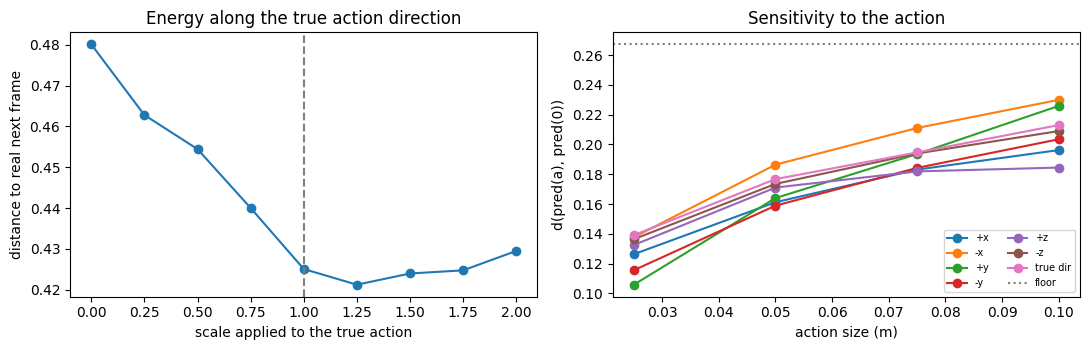

{
 "best_scale_on_true_direction (ideal 1.0)": 1.25,
 "share_of_directions_with_monotone_sensitivity": 1.0,
 "mean_sensitivity_by_size": {
  "0.025": 0.12762297902788436,
  "0.05": 0.17026206638131822,
  "0.075": 0.1917888926608222,
  "0.1": 0.20887199895722525
 }
}


In [8]:
alphas = np.linspace(0.0, 2.0, 9)
z_alpha = rollout(z0, s0, torch.stack([seq(a_gt_t * float(al)) for al in alphas]))
E_alpha = dist(z_alpha, h1.repeat(len(alphas), 1, 1)).cpu().numpy()

one_step = {}      # (direction, size) -> latent
S = {}             # sensitivity: d(pred(a), pred(0))
for name, d in DIRS.items():
    batch = torch.stack([seq(act(np.array(d) * m)) for m in MAGS])
    zs = rollout(z0, s0, batch)
    for j, m in enumerate(MAGS):
        one_step[(name, m)] = zs[j:j + 1]
        S[(name, m)] = float(dist(zs[j:j + 1], z_null))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].plot(alphas, E_alpha, marker="o")
ax[0].axvline(1.0, ls="--", c="gray"); ax[0].set_xlabel("scale applied to the true action")
ax[0].set_ylabel("distance to real next frame"); ax[0].set_title("Energy along the true action direction")
for name in DIRS:
    ax[1].plot(MAGS, [S[(name, m)] for m in MAGS], marker="o", label=name)
ax[1].axhline(ref["floor d(pred(zero), z0)"], ls=":", c="gray", label="floor")
ax[1].set_xlabel("action size (m)"); ax[1].set_ylabel("d(pred(a), pred(0))")
ax[1].set_title("Sensitivity to the action"); ax[1].legend(fontsize=7, ncol=2)
plt.tight_layout(); plt.savefig(os.path.join(OUT, "test1_dose_response.png"), dpi=160); plt.show()

monotone = float(np.mean([all(np.diff([S[(n, m)] for m in MAGS]) > 0) for n in DIRS]))
results["test1"] = {
    "best_scale_on_true_direction (ideal 1.0)": float(alphas[int(np.argmin(E_alpha))]),
    "energy_by_scale": {f"{a:.2f}": float(e) for a, e in zip(alphas, E_alpha)},
    "share_of_directions_with_monotone_sensitivity": monotone,
    "mean_sensitivity_by_size": {str(m): float(np.mean([S[(n, m)] for n in DIRS])) for m in MAGS},
}
print(json.dumps({k: v for k, v in results["test1"].items() if k != "energy_by_scale"}, indent=1))

## Test 2: Step-splitting

Same total displacement, split into `K` equal steps.

- **Gap** = distance between the one-step latent and the `K`-step latent, divided by the sensitivity of that action. 0 means splitting changes nothing. 1 means splitting changes the latent as much as the action itself does.
- **Control** = the same comparison with zero actions (`K` steps of doing nothing versus one). This is the drift caused by just taking more steps.
- **Anchor** = distance to the real next frame when the true action is split into `K` steps.

Caveat: each step stands for 0.25 s in training, so `K` steps also means more elapsed time. In a static scene with only the arm moving, the end frame should still be the same.

[INFO    ][2026-11-10 22:40:22][matplotlib.category ][update                   ] Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
[INFO    ][2026-11-10 22:40:22][matplotlib.category ][update                   ] Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


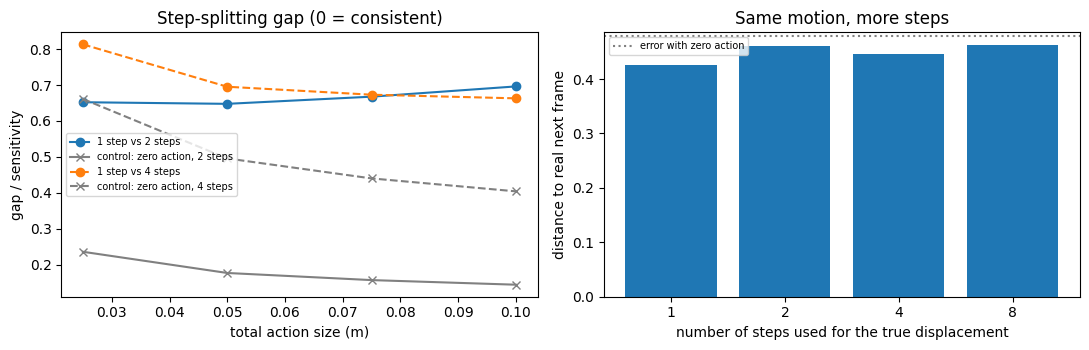

{
 "relative_gap_by_K_and_size": {
  "K=2": {
   "0.025": 0.6522670641329091,
   "0.05": 0.6477717154922891,
   "0.075": 0.6677293580154974,
   "0.1": 0.6962714509589208
  },
  "K=4": {
   "0.025": 0.813452617761128,
   "0.05": 0.6953898632768316,
   "0.075": 0.6732069453166838,
   "0.1": 0.6630656884191557
  }
 },
 "zero_action_drift_by_K": {
  "K=2": 0.030087582767009735,
  "K=4": 0.08439990878105164
 },
 "distance_to_real_next_frame_by_steps": {
  "1": 0.4250819683074951,
  "2": 0.45995864272117615,
  "4": 0.4457958936691284,
  "8": 0.46277281641960144
 }
}


In [9]:
KS = [2, 4]
split_gap, null_drift = {}, {}
for K in KS:
    zK_null = rollout(z0, s0, seq(*[ZERO] * K)[None])
    null_drift[K] = float(dist(zK_null, z_null))
    for name, d in DIRS.items():
        batch = torch.stack([seq(*[act(np.array(d) * m / K)] * K) for m in MAGS])
        zs = rollout(z0, s0, batch, chunk=4)
        for j, m in enumerate(MAGS):
            split_gap[(name, m, K)] = float(dist(zs[j:j + 1], one_step[(name, m)]))

anchor = {1: ref["error (true action, translation only)"]}
for K in [2, 4, 8]:
    zK = rollout(z0, s0, seq(*[a_gt_t / K] * K)[None], chunk=1)
    anchor[K] = float(dist(zK, h1))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for K, ls in zip(KS, ["-", "--"]):
    rel = [np.mean([split_gap[(n, m, K)] / S[(n, m)] for n in DIRS]) for m in MAGS]
    ax[0].plot(MAGS, rel, marker="o", ls=ls, label=f"1 step vs {K} steps")
    ax[0].plot(MAGS, [null_drift[K] / np.mean([S[(n, m)] for n in DIRS]) for m in MAGS], marker="x", ls=ls,
               c="gray", label=f"control: zero action, {K} steps")
ax[0].set_xlabel("total action size (m)"); ax[0].set_ylabel("gap / sensitivity")
ax[0].set_title("Step-splitting gap (0 = consistent)"); ax[0].legend(fontsize=7)
ax[1].bar([str(k) for k in anchor], list(anchor.values()))
ax[1].axhline(ref["error (zero action)"], ls=":", c="gray", label="error with zero action")
ax[1].set_xlabel("number of steps used for the true displacement"); ax[1].set_ylabel("distance to real next frame")
ax[1].set_title("Same motion, more steps"); ax[1].legend(fontsize=7)
plt.tight_layout(); plt.savefig(os.path.join(OUT, "test2_step_splitting.png"), dpi=160); plt.show()

results["test2"] = {
    "relative_gap_by_K_and_size": {f"K={K}": {str(m): float(np.mean([split_gap[(n, m, K)] / S[(n, m)] for n in DIRS]))
                                            for m in MAGS} for K in KS},
    "zero_action_drift_by_K": {f"K={K}": null_drift[K] for K in KS},
    "distance_to_real_next_frame_by_steps": {str(k): v for k, v in anchor.items()},
}
print(json.dumps(results["test2"], indent=1))

## Test 3: Path independence (step count held equal)

All paths here have exactly two steps and the same end pose, so the step-count effect from Test 2 is removed.

- `split vs front`: `(a/2, a/2)` against `(a, 0)`
- `front vs back`: `(a, 0)` against `(0, a)`
- `order`: `(x, z)` against `(z, x)`

Each gap is divided by the two-step sensitivity `d((a, 0), (0, 0))`. 0 means the path does not matter.

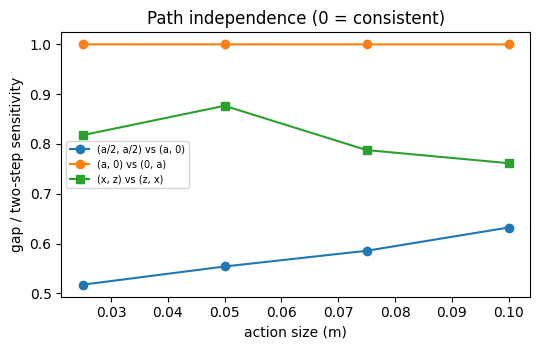

{
 "split_vs_front": {
  "0.025": 0.5173994500297288,
  "0.05": 0.553961509134164,
  "0.075": 0.5855482194534735,
  "0.1": 0.6322326351505803
 },
 "front_vs_back": {
  "0.025": 0.9999649170355668,
  "0.05": 0.9999276783226528,
  "0.075": 0.9998673939583723,
  "0.1": 0.9998232577150811
 },
 "order_x_z": {
  "0.025": 0.8176153308020541,
  "0.05": 0.8765874076640674,
  "0.075": 0.7877243936363099,
  "0.1": 0.7613665673629
 }
}


In [10]:
z_null2 = rollout(z0, s0, seq(ZERO, ZERO)[None])
path = {}
for name, d in DIRS.items():
    for m in MAGS:
        a = act(np.array(d) * m)
        zs = rollout(z0, s0, torch.stack([seq(a / 2, a / 2), seq(a, ZERO), seq(ZERO, a)]), chunk=3)
        s2 = float(dist(zs[1:2], z_null2))
        path[(name, m)] = {"S2": s2,
                           "split_vs_front": float(dist(zs[0:1], zs[1:2])) / s2,
                           "front_vs_back": float(dist(zs[1:2], zs[2:3])) / s2}

order = {}
for m in MAGS:
    ax_, az_ = act([m, 0, 0]), act([0, 0, m])
    zs = rollout(z0, s0, torch.stack([seq(ax_, az_), seq(az_, ax_)]), chunk=2)
    order[m] = float(dist(zs[0:1], zs[1:2])) / float(dist(zs[0:1], z_null2))

fig, ax = plt.subplots(figsize=(5.5, 3.6))
for key, lab in [("split_vs_front", "(a/2, a/2) vs (a, 0)"), ("front_vs_back", "(a, 0) vs (0, a)")]:
    ax.plot(MAGS, [np.mean([path[(n, m)][key] for n in DIRS]) for m in MAGS], marker="o", label=lab)
ax.plot(MAGS, [order[m] for m in MAGS], marker="s", label="(x, z) vs (z, x)")
ax.set_xlabel("action size (m)"); ax.set_ylabel("gap / two-step sensitivity")
ax.set_title("Path independence (0 = consistent)"); ax.legend(fontsize=7)
plt.tight_layout(); plt.savefig(os.path.join(OUT, "test3_path_independence.png"), dpi=160); plt.show()

results["test3"] = {
    "split_vs_front": {str(m): float(np.mean([path[(n, m)]["split_vs_front"] for n in DIRS])) for m in MAGS},
    "front_vs_back": {str(m): float(np.mean([path[(n, m)]["front_vs_back"] for n in DIRS])) for m in MAGS},
    "order_x_z": {str(m): order[m] for m in MAGS},
}
print(json.dumps(results["test3"], indent=1))

## Test 4: Reversal

`(a, -a)` should end where `(0, 0)` ends: the arm is back where it started and both paths took two steps. The gap is divided by the two-step sensitivity. 0 means the model's imagination is reversible.

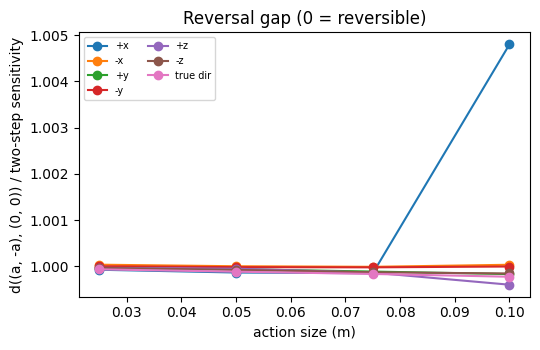

{
 "reversal_gap_by_size": {
  "0.025": 0.999969181782628,
  "0.05": 0.9999339038494737,
  "0.075": 0.9998955500161797,
  "0.1": 1.000554090978287
 }
}


In [14]:
rev = {}
rev_latent = {}
for name, d in DIRS.items():
    batch = torch.stack([seq(act(np.array(d) * m), act(-np.array(d) * m)) for m in MAGS])
    zs = rollout(z0, s0, batch, chunk=4)
    for j, m in enumerate(MAGS):
        rev[(name, m)] = float(dist(zs[j:j + 1], z_null2)) / path[(name, m)]["S2"]
        rev_latent[(name, m)] = zs[j:j + 1]

fig, ax = plt.subplots(figsize=(5.5, 3.6))
for name in DIRS:
    ax.plot(MAGS, [rev[(name, m)] for m in MAGS], marker="o", label=name)
ax.set_xlabel("action size (m)"); ax.set_ylabel("d((a, -a), (0, 0)) / two-step sensitivity")
ax.set_title("Reversal gap (0 = reversible)"); ax.legend(fontsize=7, ncol=2)
plt.tight_layout(); plt.savefig(os.path.join(OUT, "test4_reversal.png"), dpi=160); plt.show()

results["test4"] = {"reversal_gap_by_size": {str(m): float(np.mean([rev[(n, m)] for n in DIRS])) for m in MAGS}}
print(json.dumps(results["test4"], indent=1))

## Test 5: Can the planner's energy find the true direction, and does a controllability weight help?

The planner scores an action by the distance between the predicted latent and the goal latent, averaged over **all** 256 patches. Most patches are background that no action can change.

**Proposed fix (no training).** Weight each patch by how much its prediction varies across the sampled actions. The planner already computes these samples, so the weight is free. Patches the robot can affect get high weight; static background gets low weight.

Setup: 96 directions spread evenly on a sphere, all with the true action's size, plus the true direction. The goal is the real next frame. For each cost we report:

- the angle between the lowest-energy direction and the true direction (lower is better),
- the rank of the true direction among all candidates (1 is best),
- the contrast: how many standard deviations the true direction's energy sits below the mean (higher is better).

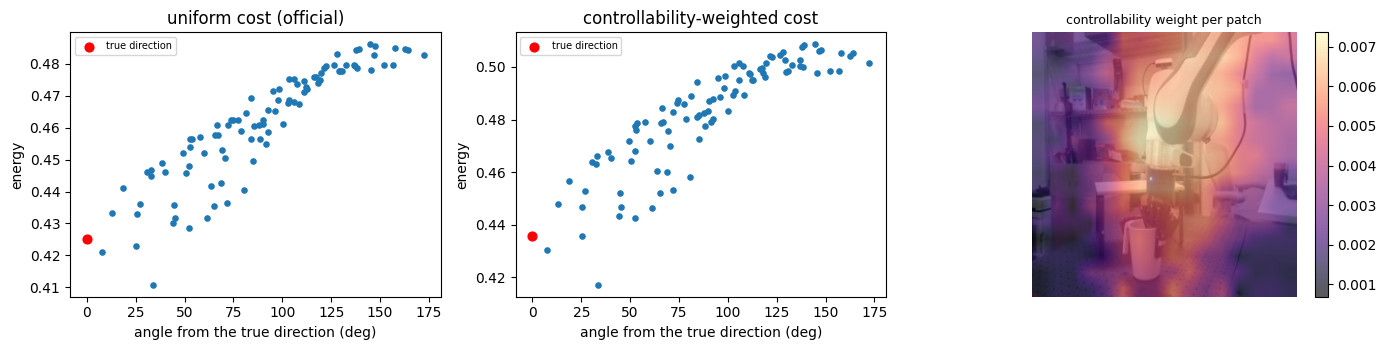

{
 "uniform_cost": {
  "angle_to_true_deg": 33.746775664921245,
  "rank_of_true_direction": 4,
  "contrast_sigma": 2.071394443511963
 },
 "controllability_weighted_cost": {
  "angle_to_true_deg": 33.746775664921245,
  "rank_of_true_direction": 4,
  "contrast_sigma": 2.270353078842163
 },
 "n_candidates": 97,
 "share_of_weight_on_top_10pct_patches": 0.16581511497497559
}


In [15]:
def fibonacci_sphere(n):
    i = np.arange(n) + 0.5
    phi = np.arccos(1 - 2 * i / n)
    theta = np.pi * (1 + 5 ** 0.5) * i
    return np.stack([np.cos(theta) * np.sin(phi), np.sin(theta) * np.sin(phi), np.cos(phi)], axis=1)


r_gt = float(a_gt_t[:3].norm())
dirs = np.concatenate([fibonacci_sphere(96), gt_dir.numpy()[None]], axis=0)   # last one is the true direction
Z = rollout(z0, s0, torch.stack([seq(act(d * r_gt)) for d in dirs]))          # [97, N, D]

per_token = (Z - h1).abs().mean(dim=-1)                 # [97, N] error of each patch for each candidate
w = Z.std(dim=0).mean(dim=-1)                           # [N] how much each patch depends on the action
w = w / w.sum()
E_uniform = per_token.mean(dim=1).cpu().numpy()
E_weighted = (per_token * w[None]).sum(dim=1).cpu().numpy()


def score(E):
    best = dirs[int(np.argmin(E))]
    angle = float(np.degrees(np.arccos(np.clip(best @ gt_dir.numpy(), -1, 1))))
    rank = int((E < E[-1]).sum()) + 1
    contrast = float((E[:-1].mean() - E[-1]) / (E[:-1].std() + 1e-12))
    return {"angle_to_true_deg": angle, "rank_of_true_direction": rank, "contrast_sigma": contrast}


results["test5"] = {"uniform_cost": score(E_uniform), "controllability_weighted_cost": score(E_weighted),
                    "n_candidates": len(dirs),
                    "share_of_weight_on_top_10pct_patches": float(torch.sort(w, descending=True).values[: len(w) // 10].sum())}

cosang = dirs @ gt_dir.numpy()
ang = np.degrees(np.arccos(np.clip(cosang, -1, 1)))
fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
for i, (E, t) in enumerate([(E_uniform, "uniform cost (official)"), (E_weighted, "controllability-weighted cost")]):
    ax[i].scatter(ang, E, s=14); ax[i].scatter([0], [E[-1]], c="red", s=40, label="true direction")
    ax[i].set_xlabel("angle from the true direction (deg)"); ax[i].set_ylabel("energy"); ax[i].set_title(t); ax[i].legend(fontsize=7)
up = F.interpolate(w.view(1, 1, grid, grid).float().cpu(), size=(crop_size, crop_size), mode="bilinear")[0, 0].numpy()
ax[2].imshow(np_clips[0, 0]); im = ax[2].imshow(up, alpha=0.65, cmap="magma"); ax[2].axis("off")
ax[2].set_title("controllability weight per patch", fontsize=9); plt.colorbar(im, ax=ax[2], fraction=0.046)
plt.tight_layout(); plt.savefig(os.path.join(OUT, "test5_direction_and_weighting.png"), dpi=160); plt.show()
print(json.dumps(results["test5"], indent=1))

## Where do the inconsistencies live?

Per-patch maps over the context frame, for the true direction at 0.075 m. If the gaps sit on the arm, the model is unsure about the thing it is supposed to control. If they are spread over the background, the rollout is drifting everywhere.

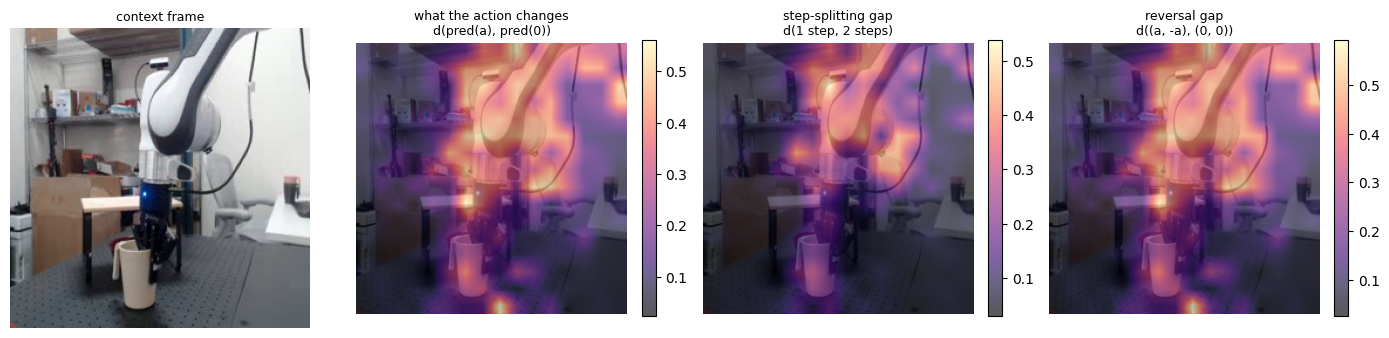

{
 "corr(action effect, splitting gap)": 0.7822787135517836,
 "corr(action effect, reversal gap)": 0.9995271493994459
}


In [16]:
m_show = 0.075
a_show = act(gt_dir * m_show)
z_one = one_step[("true dir", m_show)]
z_two = rollout(z0, s0, seq(a_show / 2, a_show / 2)[None])
maps = {
    "what the action changes\nd(pred(a), pred(0))": token_map(z_one, z_null)[0],
    "step-splitting gap\nd(1 step, 2 steps)": token_map(z_one, z_two)[0],
    "reversal gap\nd((a, -a), (0, 0))": token_map(rev_latent[("true dir", m_show)], z_null2)[0],
}
fig, ax = plt.subplots(1, 4, figsize=(14, 3.6))
ax[0].imshow(np_clips[0, 0]); ax[0].set_title("context frame", fontsize=9); ax[0].axis("off")
for i, (t, mp) in enumerate(maps.items(), start=1):
    up = F.interpolate(mp[None, None].float().cpu(), size=(crop_size, crop_size), mode="bilinear")[0, 0].numpy()
    ax[i].imshow(np_clips[0, 0]); im = ax[i].imshow(up, alpha=0.65, cmap="magma")
    ax[i].set_title(t, fontsize=9); ax[i].axis("off"); plt.colorbar(im, ax=ax[i], fraction=0.046)
plt.tight_layout(); plt.savefig(os.path.join(OUT, "spatial_maps.png"), dpi=160); plt.show()

flat = {k: v.flatten().float().cpu().numpy() for k, v in maps.items()}
keys = list(flat)
results["spatial"] = {
    "corr(action effect, splitting gap)": float(np.corrcoef(flat[keys[0]], flat[keys[1]])[0, 1]),
    "corr(action effect, reversal gap)": float(np.corrcoef(flat[keys[0]], flat[keys[2]])[0, 1]),
}
print(json.dumps(results["spatial"], indent=1))

In [17]:
# --- Save everything ---
results["meta"] = {"smoke_test": SMOKE_TEST, "device": device, "sizes_m": MAGS, "directions": list(DIRS),
                   "checkpoint": None if SMOKE_TEST else CKPT_URL}
with open(os.path.join(OUT, "audit_results.json"), "w") as f:
    json.dump(results, f, indent=1)
print("saved to", OUT, "->", sorted(os.listdir(OUT)))
if SMOKE_TEST:
    print("\nSMOKE TEST: random weights. These numbers are not results.")

saved to /content/vjepa2/audit_outputs -> ['audit_results.json', 'spatial_maps.png', 'test1_dose_response.png', 'test2_step_splitting.png', 'test3_path_independence.png', 'test4_reversal.png', 'test5_direction_and_weighting.png']


## Test 6: Which rollout position ignores the action?

Tests 3 and 4 gave ratios of exactly 1.000, which suggested that the second action of a two-step rollout has no effect. Here the same action is placed at step 1, 2 or 3 of a three-step rollout, and the final latent is compared with doing nothing. The test is repeated with pose updates frozen, to check whether the action's effect is carried by the pose token.

In [18]:
# Test 6: does the last action of a rollout matter?
@torch.no_grad()
def rollout_v(z0, s0, action_seq, freeze_pose=False):
    B, K, _ = action_seq.shape
    acts = action_seq.to(device=z0.device, dtype=z0.dtype)
    z, s = z0.repeat(B, 1, 1), s0.repeat(B, 1, 1)
    for k in range(K):
        a = acts[:, :k + 1]
        zn = F.layer_norm(predictor(z, a, s)[:, -tokens_per_frame:], (z.size(-1),))
        sn = s[:, -1:] if freeze_pose else compute_new_pose(s[:, -1:], a[:, -1:])
        z, s = torch.cat([z, zn], 1), torch.cat([s, sn], 1)
    return z[:, -tokens_per_frame:]

res6 = {}
for freeze in [False, True]:
    for m in MAGS:
        a = act(gt_dir * m)
        zs = rollout_v(z0, s0, torch.stack([seq(ZERO, ZERO, ZERO), seq(a, ZERO, ZERO),
                                            seq(ZERO, a, ZERO), seq(ZERO, ZERO, a)]), freeze_pose=freeze)
        res6[f"freeze_pose={freeze}, size={m}"] = {
            "action at step 1": float(dist(zs[1:2], zs[0:1])),
            "action at step 2": float(dist(zs[2:3], zs[0:1])),
            "action at step 3 (last)": float(dist(zs[3:4], zs[0:1])),
        }

results["test6_last_action"] = res6
with open(os.path.join(OUT, "audit_results.json"), "w") as f:
    json.dump(results, f, indent=1)
print(json.dumps(res6, indent=1))

{
 "freeze_pose=False, size=0.025": {
  "action at step 1": 0.13774120807647705,
  "action at step 2": 0.0038644808810204268,
  "action at step 3 (last)": 0.13572362065315247
 },
 "freeze_pose=False, size=0.05": {
  "action at step 1": 0.17695176601409912,
  "action at step 2": 0.007551408838480711,
  "action at step 3 (last)": 0.1781984269618988
 },
 "freeze_pose=False, size=0.075": {
  "action at step 1": 0.20044417679309845,
  "action at step 2": 0.011013785377144814,
  "action at step 3 (last)": 0.2028527706861496
 },
 "freeze_pose=False, size=0.1": {
  "action at step 1": 0.22545665502548218,
  "action at step 2": 0.014225277118384838,
  "action at step 3 (last)": 0.2200482338666916
 },
 "freeze_pose=True, size=0.025": {
  "action at step 1": 0.13751186430454254,
  "action at step 2": 0.002944918582215905,
  "action at step 3 (last)": 0.13572362065315247
 },
 "freeze_pose=True, size=0.05": {
  "action at step 1": 0.17652517557144165,
  "action at step 2": 0.00570759316906333,
  "a

## Test 7: Position sweep over six steps

Same idea over six steps, to tell apart three patterns: only step 2 is ignored, every second step is ignored, or something else.

In [19]:
# Test 7: effect of the same action placed at each position of a 6-step rollout
res7 = {}
K = 6
for m in [0.05, 0.1]:
    a = act(gt_dir * m)
    batch = [seq(*[ZERO] * K)]
    for p in range(K):
        steps = [ZERO] * K
        steps[p] = a
        batch.append(seq(*steps))
    zs = rollout_v(z0, s0, torch.stack(batch))
    res7[f"size={m}"] = {f"action at step {p + 1}": float(dist(zs[p + 1:p + 2], zs[0:1])) for p in range(K)}

results["test7_position_sweep"] = res7
with open(os.path.join(OUT, "audit_results.json"), "w") as f:
    json.dump(results, f, indent=1)
print(json.dumps(res7, indent=1))

{
 "size=0.05": {
  "action at step 1": 0.17980560660362244,
  "action at step 2": 0.011219295673072338,
  "action at step 3": 0.18049557507038116,
  "action at step 4": 0.178527370095253,
  "action at step 5": 0.1749245971441269,
  "action at step 6": 0.1711069792509079
 },
 "size=0.1": {
  "action at step 1": 0.2415177822113037,
  "action at step 2": 0.019142840057611465,
  "action at step 3": 0.24038219451904297,
  "action at step 4": 0.2346298098564148,
  "action at step 5": 0.2282240241765976,
  "action at step 6": 0.2173188179731369
 }
}


## How to read the results

- **Test 1.** If the best scale is far from 1.0, or sensitivity is flat, the predictor is partly ignoring the action. That is the failure an action-swap regulariser targets.
- **Test 2.** A splitting gap well above the zero-action control means the model's one-step and multi-step predictions disagree about the same motion. That gap is exactly the loss a horizon-consistent ("shortcut") predictor would minimise.
- **Test 3.** With step count held equal, any remaining gap is pure path dependence.
- **Test 4.** A large reversal gap means a forward-then-back check carries information, so it can serve as a free uncertainty score for the planner. In this run, the ratios in tests 3 and 4 equal 1.000, which tests 6 and 7 trace to the step-2 anomaly, so test 4 does not measure reversibility here.
- **Test 5.** If the weighted cost gives a smaller angle, a better rank or a higher contrast than the uniform cost, the planner's energy can be sharpened for free. If the lowest-energy direction is far from the true one under both costs, the model's sense of the action axes is off for this camera, which is the camera-sensitivity limitation the paper reports.
- **Tests 6 and 7.** In this run, the same action changes the final latent by 0.17 to 0.24 at steps 1 and 3 to 6, but only 0.011 to 0.019 at step 2. Freezing the pose barely changes this. A hypothesis, not yet tested: in `app/vjepa_droid/train.py`, step 2 is the only position that also receives the autoregressive rollout loss (`auto_steps: 2`).
- **Maps.** A high correlation between the action-effect map and the gap maps means the inconsistency is concentrated on the arm.

**Limits.** One scene, one transition, free-space motion, translation-only actions, no gripper change. The next step is to repeat this on a few hundred DROID transitions and report means with confidence intervals.